In [2]:
import pandas as pd 

In [3]:
df = pd.read_csv("data/student_data.csv")

In [4]:
df.head()

,hours_studied,attendance,exam_score
0,1,60,25
1,2,65,30
2,3,70,38
3,4,75,45
4,5,80,55


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   hours_studied  50 non-null     int64
 1   attendance     50 non-null     int64
 2   exam_score     50 non-null     int64
dtypes: int64(3)
memory usage: 1.3 KB


In [6]:
df.isnull().sum()

hours_studied    0
attendance       0
exam_score       0
dtype: int64

<Axes: xlabel='hours_studied', ylabel='exam_score'>

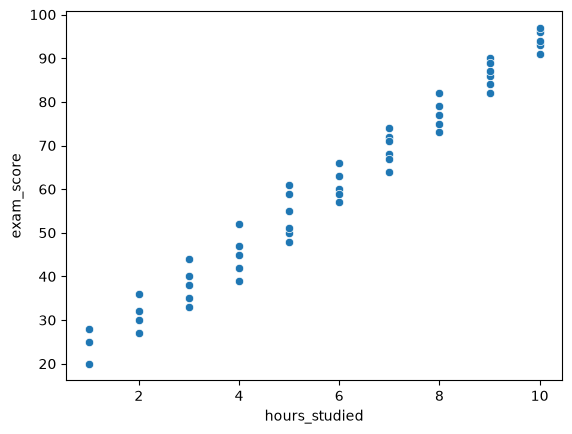

In [7]:
import seaborn as sns

sns.scatterplot(data=df,x=df['hours_studied'],y=df['exam_score'])

In [8]:
df.columns

Index(['hours_studied', 'attendance', 'exam_score'], dtype='str')

In [9]:
x = df[['hours_studied','attendance']]
y = df['exam_score']

In [10]:
from sklearn.model_selection import train_test_split

x_train , x_test ,y_train, y_test  = train_test_split(x,y,train_size=0.7)

In [11]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[7.06,0.3 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['hours_studied','attendance']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.325
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [12]:
y_pred = model.predict(x_test)

In [13]:
result = pd.DataFrame({
    "actual_predittion": y_test,
    "ai_prediction": y_pred
})

result

,actual_predittion,ai_prediction
31,51,51.271986
0,25,20.661036
33,64,62.991363
15,68,69.565878
8,90,88.457452
37,36,36.083655
48,71,71.358927
39,52,50.791447
29,33,33.276937
28,94,93.121774


In [ ]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

print("R2 Score:", r2_score(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))


gradient descent: [7.05505449 0.29884158]
R2 Score: 0.9942177117607826
MSE: 2.5464169443160003
MAE: 1.1186627636951088


In [ ]:
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

Intercept: -4.3245131973461355
Coefficients: [7.05505449 0.29884158]
